# 🏠 German Rental Price Classification: Exploratory Data Analysis

**Input:** `data/processed/immo_clean.csv`, created by `01_data_preparation.ipynb` (cleaned data with the target `rentClass`).

**Goal of this notebook:** find which features separate Low, Medium and High rent flats (Phase 6).

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Show big numbers normally instead of scientific notation
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.max_columns", None)

In [2]:
# Load the clean data saved at the end of 01_data_preparation.ipynb
df_clean = pd.read_csv("../data/processed/immo_clean.csv")

# A CSV stores rentClass as plain text, so pandas forgets the order Low < Medium < High
# (it would sort alphabetically: High, Low, Medium). This restores the correct order.
df_clean["rentClass"] = pd.Categorical(df_clean["rentClass"],
                                       categories=["Low", "Medium", "High"], ordered=True)

print("Shape:", df_clean.shape)
df_clean["rentClass"].value_counts().sort_index()

Shape: (267855, 26)


rentClass
Low       89364
Medium    89206
High      89285
Name: count, dtype: int64

## 6. Exploratory Data Analysis
### 6.1 Yes/no features vs rent class
Why do EDA before modeling?
Insights for the report. The model predicts; EDA explains.
Check our hypotheses (you guessed state, year built and size).
Choose features for the model. Features that don't separate the classes are candidates to drop.
Catch problems we missed, such as strange patterns or hidden leakage.


In [3]:
def class_shares(col):
    table = pd.crosstab(df_clean[col], df_clean["rentClass"], normalize="index") * 100
    return table.round(1)

# Example: lift
class_shares("lift")

rentClass,Low,Medium,High
lift,,,
False,39.3,35.9,24.8
True,14.0,25.0,61.1


In [4]:
bool_cols = ["newlyConst", "lift", "hasKitchen", "balcony", "garden",
             "cellar", "hasParking", "wasRefurbished"]

rows = []                                          # start with an empty list
for col in bool_cols:
    table = class_shares(col)                      # the crosstab for this feature
    rows.append({                                  # add one row of results
        "feature":    col,
        "High_% if yes": table.loc[True, "High"],  # % High among flats WITH it
        "High_% if no":  table.loc[False, "High"], # % High among flats WITHOUT it
    })

bool_summary = pd.DataFrame(rows)                  # turn the list of rows into a table
bool_summary["difference"] = bool_summary["High_% if yes"] - bool_summary["High_% if no"]
bool_summary.sort_values("difference", ascending=False)

# big positive → the feature goes with expensive flats
# near 0 → the feature doesn't matter
# negative → the feature goes with cheaper flats


,feature,High_% if yes,High_% if no,difference
0,newlyConst,83.9,29.0,54.9
1,lift,61.1,24.8,36.3
2,hasKitchen,56.5,21.3,35.2
6,hasParking,47.2,26.4,20.8
3,balcony,39.2,23.9,15.3
7,wasRefurbished,36.7,31.9,4.8
4,garden,32.3,33.6,-1.3
5,cellar,32.2,35.3,-3.1


**Insights (yes/no features):**
- **Strongest:** `newlyConst`, `lift` and `hasKitchen` go with High-rent flats (largest differences in % High).
- **Weak:** `wasRefurbished` barely separates the classes (difference ≈ 4 points).
- **Surprise:** `garden` goes with slightly *cheaper* flats (−3.1). Likely explanation: gardens are more common outside expensive city centres, so **location** (a confounding factor) drives both.
- ⚠️ **Correlation is not causation:** e.g. a fitted kitchen may be a *sign* of an upscale flat rather than the *cause* of high rent.

### 6.2 Category features vs rent class


A-location(state)

In [5]:
class_shares("regio1").sort_values("High", ascending=False)


rentClass,Low,Medium,High
regio1,,,
Hamburg,0.3,6.0,93.6
Berlin,0.6,13.8,85.6
Baden_Württemberg,2.2,25.5,72.3
Bayern,5.1,23.2,71.6
Hessen,6.0,23.4,70.7
Schleswig_Holstein,11.5,49.4,39.1
Bremen,26.7,35.7,37.6
Rheinland_Pfalz,18.1,44.6,37.3
Niedersachsen,29.5,42.7,27.7


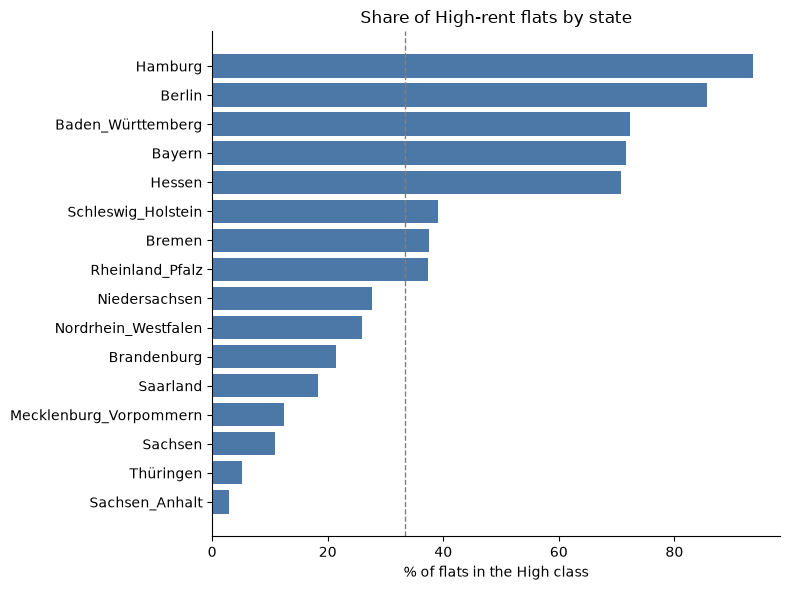

In [6]:
high_by_state = class_shares("regio1")["High"].sort_values()   # ← this line was missing

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(high_by_state.index, high_by_state.values, color="#4C78A8")
ax.axvline(33.3, color="gray", linestyle="--", linewidth=1)
ax.set_title("Share of High-rent flats by state")
ax.set_xlabel("% of flats in the High class")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../reports/figures/high_share_by_state.png", dpi=150)
plt.show()


B-location(district) With 146 districts, we look at the 10 most and 10 least expensive:

In [7]:
by_district = class_shares("regio2").sort_values("High", ascending=False)
print("Most expensive districts:")
display(by_district.head(10))
print("Cheapest districts:")
display(by_district.tail(10))

Most expensive districts:


rentClass,Low,Medium,High
regio2,,,
München,0.0,0.0,100.0
München_Kreis,0.0,0.0,100.0
Stuttgart,0.0,0.8,99.2
Frankfurt_am_Main,0.0,1.2,98.8
Heidelberg,0.0,2.9,97.1
Mainz,0.1,4.3,95.5
Ingolstadt,0.0,5.2,94.8
Hamburg,0.3,6.0,93.6
Köln,0.3,7.7,92.0


Cheapest districts:


rentClass,Low,Medium,High
regio2,,,
Plauen,93.0,6.6,0.3
Vogtlandkreis,92.9,6.8,0.3
Zwickau_Kreis,93.2,6.5,0.3
Görlitz_Kreis,95.5,4.2,0.3
Görlitz,85.1,14.7,0.2
Mansfeld_Südharz_Kreis,90.8,9.1,0.1
Burgenlandkreis,84.8,15.2,0.0
Altenburger_Land_Kreis,93.7,6.3,0.0
Greiz_Kreis,95.1,4.9,0.0


Part C: the property features

In [8]:
for col in ["condition", "interiorQual", "typeOfFlat", "heatingType", "petsAllowed"]:
    print(f"\n=== {col} ===")
    display(class_shares(col).sort_values("High", ascending=False))



=== condition ===


rentClass,Low,Medium,High
condition,,,
first_time_use,2.0,16.2,81.9
mint_condition,9.6,27.3,63.1
first_time_use_after_refurbishment,19.2,36.4,44.4
modernized,36.5,35.9,27.6
unknown,38.9,34.3,26.9
fully_renovated,39.5,33.9,26.6
well_kept,37.7,38.8,23.4
refurbished,51.8,32.1,16.1
need_of_renovation,60.9,29.9,9.2



=== interiorQual ===


rentClass,Low,Medium,High
interiorQual,,,
luxury,1.1,13.3,85.6
sophisticated,10.6,31.4,57.9
unknown,38.5,33.9,27.5
simple,50.2,30.5,19.4
normal,46.7,35.9,17.4



=== typeOfFlat ===


rentClass,Low,Medium,High
typeOfFlat,,,
penthouse,1.1,16.2,82.7
terraced_flat,9.2,28.8,62.0
loft,9.7,32.6,57.7
maisonette,16.1,38.1,45.8
half_basement,17.1,40.0,42.9
other,34.9,29.4,35.8
ground_floor,29.7,36.4,33.9
apartment,33.8,33.4,32.8
raised_ground_floor,33.7,33.6,32.7



=== heatingType ===


rentClass,Low,Medium,High
heatingType,,,
floor_heating,3.1,21.8,75.1
combined_heat_and_power_plant,7.7,19.7,72.6
heat_pump,3.0,27.2,69.8
wood_pellet_heating,6.2,29.7,64.1
other,27.8,36.7,35.5
unknown,36.3,28.8,34.9
gas_heating,28.0,39.4,32.5
district_heating,42.9,25.7,31.4
electric_heating,29.0,40.2,30.8



=== petsAllowed ===


rentClass,Low,Medium,High
petsAllowed,,,
no,12.9,35.9,51.1
unknown,34.8,33.7,31.5
negotiable,41.6,31.9,26.5
yes,46.4,28.3,25.3


Part D


In [9]:
cat_features = ["regio1", "regio2", "condition", "interiorQual", "typeOfFlat", "heatingType", "petsAllowed"]

spread = {}
for col in cat_features:
    high = class_shares(col)["High"]
    spread[col] = high.max() - high.min()

pd.Series(spread).sort_values(ascending=False).round(1)

regio2         100.0
regio1          90.7
condition       72.7
interiorQual    68.2
heatingType     58.4
typeOfFlat      55.0
petsAllowed     25.8
dtype: float64

How to read the spread (Part D)
The spread compares rows (groups) inside the High column:

Example with interiorQual:

interiorQual	High %
luxury	86 ← most expensive group (max)
sophisticated	58
unknown	33
simple	19
normal	17 ← cheapest group (min)
Spread = 86 − 17 = 69 points

So it's a row gap: the highest row minus the lowest row, within the High column only.

Spread	Meaning
Large (for example 60–90)	Some groups are almost all expensive, others almost all cheap → strong separator
Small (for example 10)	All groups have similar % High → weak separator

regio1: Hamburg is mostly High, while the eastern states have very few High flats → a very large gap
regio2: some districts have almost no Low flats, others almost no High → probably the largest gap of all
So the expected ranking is:

Rank	Feature	Type
1–2	regio2, regio1	Location
3–5	interiorQual, condition, typeOfFlat	Property (your picks ✅)
last	petsAllowed, heatingType (probably)	Weak

Rule !!!!!!!!!!!!!!!!!!!

Number of groups	How to check	What you compare
Few (for example interiorQual, 5 groups)	Look at the whole table, sorted by High	max − min of the High column

Many (for example regio2, 146 groups)	Look at .head() (most expensive) and .tail() (cheapest)	The High % at the top vs at the bottom

**How to judge if a category feature separates the classes:**
1. Sort the crosstab by % High (few groups → whole table; many groups → head + tail).
2. Gap = % High of the most expensive group − % High of the cheapest group. Big gap = good separator.
3. Check the extreme groups have enough flats (small groups can be extreme by luck).
4. Check how many groups are far from 33%, not just the two ends.

**Insights (category features):**
- **Location is the strongest separator.** City-states (Hamburg, Berlin) and the economically strong south (Bavaria, Baden-Württemberg) have the most High-rent flats; the eastern states (e.g. Saxony-Anhalt, Thuringia) very few. Berlin is in the east but expensive, so "big city" beats "region".
- **District (`regio2`) separates even more than state:** some districts have almost no Low flats, others almost no High, which confirms keeping it in step 3.7.
- **Property features:** `interiorQual`, `condition` and `typeOfFlat` separate well. Interior quality rises clearly from normal → sophisticated → luxury; "simple" ≈ "normal"; "unknown" sits in the middle (a weak clue).
- **Weakest:** `petsAllowed`, `heatingType` (check the spread numbers).


### 6.3 Number features vs rent class

In [10]:
num_features = ["yearConstructed", "livingSpace", "noRooms", "floor",
                "numberOfFloors", "thermalChar", "picturecount", "pricetrend"]

# Median of each feature in each class; .T flips it so each feature is a row
medians = df_clean.groupby("rentClass")[num_features].median().T

# How much higher (or lower) is High than Low?
medians["High − Low"] = medians["High"] - medians["Low"]
medians.round(1)

#  The features have different units (years, m², rooms), so you can't compare the High − Low numbers between features. A gap of 30 years isn't "bigger" than 10 m². Look at each feature on its own: is the change large for that feature?

rentClass,Low,Medium,High,High − Low
yearConstructed,"1,965.0","1,969.0","1,997.0",32.0
livingSpace,62.6,68.9,75.0,12.4
noRooms,3.0,3.0,2.5,-0.5
floor,2.0,2.0,2.0,0.0
numberOfFloors,3.0,3.0,3.0,0.0
thermalChar,109.0,114.4,88.7,-20.3
picturecount,8.0,9.0,10.0,2.0
pricetrend,1.9,3.4,4.6,2.7


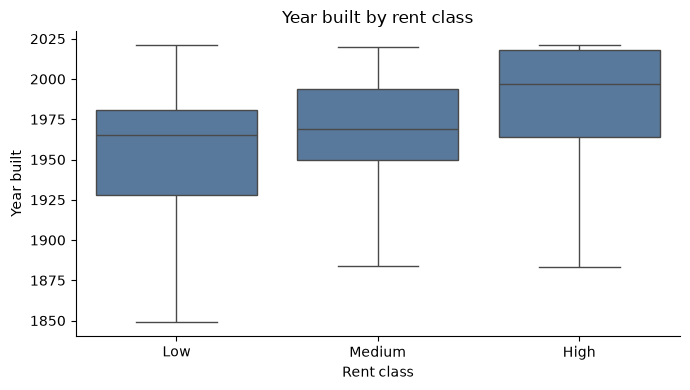

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df_clean, x="rentClass", y="yearConstructed",
            color="#4C78A8", showfliers=False, ax=ax)
ax.set_title("Year built by rent class")
ax.set_xlabel("Rent class")
ax.set_ylabel("Year built")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../reports/figures/year_built_by_class.png", dpi=150)
plt.show()

In [12]:
size_groups = pd.cut(df_clean["livingSpace"],
                     bins=[0, 40, 60, 80, 100, 150, 400],
                     labels=["<40", "40–60", "60–80", "80–100", "100–150", "150+"])

(pd.crosstab(size_groups, df_clean["rentClass"], normalize="index") * 100).round(1)


rentClass,Low,Medium,High
livingSpace,,,
<40,20.7,28.2,51.2
40–60,45.3,32.8,21.9
60–80,40.7,34.1,25.2
80–100,23.2,36.2,40.6
100–150,15.7,33.4,51.0
150+,13.1,29.5,57.4


**Insights (number features):**
- **Year built is the strongest number feature:** a typical High-rent flat was built around **1997**, compared with **1965** for Low-rent flats (a generation newer).
- **Boxplot:** medians rise clearly from Low → Medium → High, but the boxes **overlap**, so year built pushes a flat towards a class but cannot decide it alone.
- **Living space: positive but weak.** High-rent flats are ~12 m² larger (median), and larger size groups have more High flats. Correlation is only 0.1 because individual flats vary a lot: the trend is real on average but noisy.
- **Hypothesis check:** `yearConstructed` ✅ confirmed as a top clue; `livingSpace` ⚠️ only partly: it has the right direction but is a weak clue.
- **Lesson:** weak correlation ≠ no relationship; it means a noisy relationship.


### 6.4 Correlation between number features
Checks whether two features carry the same information (redundancy). Rule of thumb: > 0.8 = largely redundant.

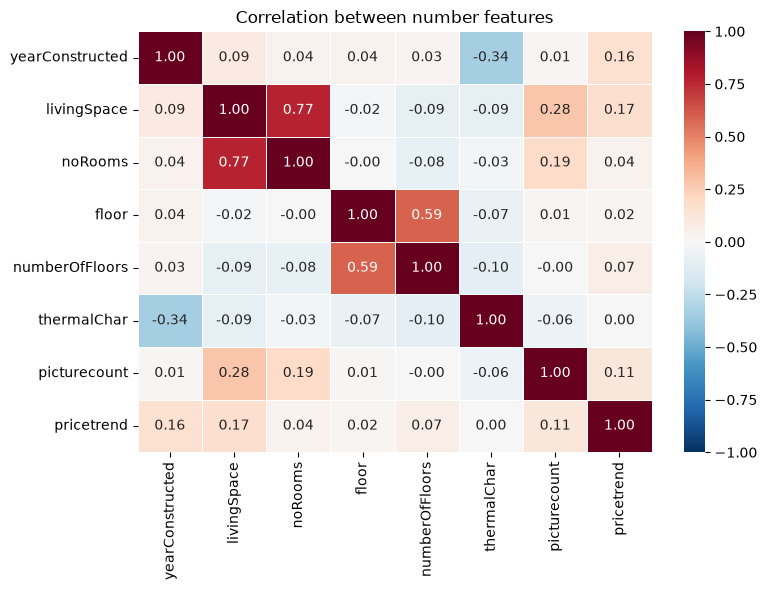

In [13]:
# Correlation of every number feature with every other one
corr_matrix = df_clean[num_features].corr().round(2)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix,
            annot=True, fmt=".2f",           # write the number in each cell
            cmap="RdBu_r", center=0,         # blue = negative, white = 0, red = positive
            vmin=-1, vmax=1,                 # fix the colour scale from -1 to 1
            linewidths=0.5, ax=ax)
ax.set_title("Correlation between number features")
plt.tight_layout()
plt.savefig("../reports/figures/feature_correlation.png", dpi=150)
plt.show()


**Insights (correlation between features):**
- Highest pair: `noRooms` & `livingSpace` (bigger flats have more rooms). `floor` & `numberOfFloors` = 0.59 (moderate: high floors need tall buildings).
- No pair above 0.8, so no feature is redundant and all number features are kept.


### 6.5 Two features together (controlling for location)
Test: does a feature's effect hold **within each state**, or was it caused by location?


In [ ]:
# Step 1: mark the High flats (True / False)
is_high = df_clean["rentClass"] == "High"

def high_share_by_state(feature):
    # Step 2: split the flats by STATE and by the FEATURE at the same time,
    #         then calculate % High in each small group
    # unstack turns the table from "long" to "wide" format, so each feature value gets its own column
    table = is_high.groupby([df_clean["regio1"], df_clean[feature]]).mean().unstack() * 100

    # Step 3: inside each state, % High WITH the feature minus % High WITHOUT it
    table["difference"] = table[True] - table[False]

    return table.round(1).sort_values("difference")

high_share_by_state("garden")


garden,False,True,difference
regio1,,,
Saarland,20.1,9.9,-10.2
Hessen,71.9,65.4,-6.5
Rheinland_Pfalz,38.3,33.1,-5.3
Niedersachsen,28.6,24.5,-4.1
Baden_Württemberg,73.0,69.0,-4.0
Bayern,72.5,68.7,-3.8
Sachsen,11.2,10.4,-0.8
Sachsen_Anhalt,2.9,2.6,-0.3
Schleswig_Holstein,38.9,39.9,0.9


**Insights (two features together, controlling for location):**
- **New builds: a real, consistent effect.** New flats are more often High in **all 16 states**. Strongest in cheap regions (Saxony: 81% High for new vs 8% for old); weakest in Hamburg (+3.3), where almost every flat is already High (**ceiling effect**).
- **Garden: no consistent effect.** Positive in 8 states, negative in 8. Higher rents in Brandenburg (+21.7, wealthy suburbs around Berlin) and Berlin (+10.0); lower in Hesse (−6.5) and Bavaria (−3.8), where garden flats are likely outside expensive cities. The small overall effect (−1.3) hid these opposite patterns.
- **Lesson:** a result that holds **within every group** is strong evidence. When the direction flips between groups, the effect **depends on another feature** (an **interaction**); here, location changes what a garden means.
